In [17]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from PIL import Image
import torchvision
from torchvision.transforms import v2

import numpy as np
import os
import matplotlib.pyplot as plt

In [4]:
data_train = torchvision.datasets.MNIST(root='data', train=True, download=True)
data_test = torchvision.datasets.MNIST(root='data', train=False, download=True)

print(data_train[8])

(<PIL.Image.Image image mode=L size=28x28 at 0x1FD54047D10>, 1)


In [5]:
MNIST_ROOT = './mnist_folder'

def save_mnist_to_folder(mnist_dataset, split_name, root_dir):
    split_dir = os.path.join(root_dir, split_name)

    for label in range(10):
        os.makedirs(os.path.join(split_dir, str(label)), exist_ok=True)

    for idx, (image, label) in enumerate(mnist_dataset):
        path = os.path.join(split_dir, str(label), f"img_{idx:05d}.png")
        image.save(path)

save_mnist_to_folder(data_train, 'train', MNIST_ROOT)
save_mnist_to_folder(data_test, 'test', MNIST_ROOT)

In [6]:
class MNISTDataset(Dataset):
    def __init__(self, root_dir, transfoms=None):
        self.root_dir = root_dir
        self.transfoms = transfoms

        self.image_path = []
        self.labels = []

        class_folders = sorted(os.listdir(root_dir))

        self.class_to_idx = {
            folder_name: idx for idx, folder_name in enumerate(class_folders)
        }

        for folder_name in class_folders:
            folder_path = os.path.join(root_dir, folder_name)

            label = self.class_to_idx[folder_name]

            for filename in os.listdir(folder_path):
                if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                    self.image_path.append(os.path.join(folder_path, filename))
                    self.labels.append(label)

    def __len__(self):
        return len(self.image_path)

    def __getitem__(self, idx):
        img_path = self.image_path[idx]
        label = self.labels[idx]

        image = Image.open(img_path)

        if self.transfoms:
            image = self.transfoms(image)

        return image, torch.tensor(label, dtype=torch.long)

In [12]:
train_transforms = v2.Compose([
    v2.ToImage(),
    v2.Resize((28, 28)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(0.1307,), std=(0.3081,))
])

test_transforms = v2.Compose([
    v2.ToImage(),
    v2.Resize((28, 28)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(0.1307,), std=(0.3081,))
])

Image: torch.Size([1, 28, 28]), label: 0


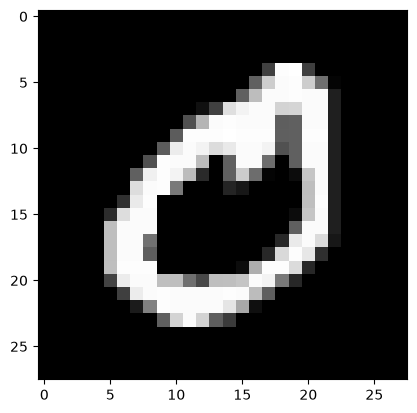

In [ ]:
train_dir = os.path.join(MNIST_ROOT, 'train')
mnist_train_dataset = MNISTDataset(root_dir=train_dir, transfoms=train_transforms)

test_dir = os.path.join(MNIST_ROOT, 'test')
mnist_test_dataset = MNISTDataset(root_dir=test_dir, transfoms=test_transforms)

image, label = mnist_train_dataset[1]

print(f'Image: {image.size()}, label: {label.item()}') # type: ignore

plt.imshow(image.numpy().squeeze(), cmap='gray') # type: ignore

In [18]:
train_loader = DataLoader(
    dataset=mnist_train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    dataset=mnist_test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

In [ ]:
class my_model(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.2)

        self.conv1 = nn.Conv2d(in_channels=in_features, out_channels=32, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        # (bs, 64, 28, 28)
        self.flatten = nn.Flatten()
        # (bs, 64 * 28 * 28)

        self.fc1 = nn.Linear(in_features=64 * 28 * 28, out_features=128)
        self.fc2 = nn.Linear(in_features=128, out_features=64)
        self.fc3 = nn.Linear(in_features=64, out_features=out_features)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)

        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [ ]:
model = my_model(in_features=1, out_features=10)
result = model(mnist_train_dataset[0][0].unsqueeze(0)) # type: ignore

print(result.shape)

torch.Size([1, 10])
